In [1]:
import pandas as pd
import numpy as np

In [30]:
CSV_PATHS = [
    "results_gpt-4o_20260625_1826.csv",
    "results_gpt-4o-mini_20260625_1838.csv",
    "results_meta-llama_Meta-Llama-3.1-8B-Instruct_20260625_1930.csv",
    "results_Qwen_Qwen2.5-7B-Instruct_20260625_1925.csv",
    "results_Qwen_Qwen3-14B_20260625_1902.csv",
]

In [31]:
dfs = []

for path in CSV_PATHS:

    df_model = pd.read_csv(path)

    # opcional: guardar origem do arquivo
    df_model["source_file"] = path

    dfs.append(df_model)

# concatena tudo
df = pd.concat(dfs, ignore_index=True)

# garante tipos corretos
df["deepeval_score"] = pd.to_numeric(
    df["deepeval_score"],
    errors="coerce"
)

print(df.shape)
print(df.columns.tolist())

print("\n=== MODELS ===")
print(df["model"].value_counts())

(400, 16)
['provider', 'model', 'temperature', 'case_id', 'case_type', 'query', 'run', 'expected_tool_call', 'actual_tool_call', 'deterministic_correct', 'failure_type', 'tool_calls_info', 'final_content', 'deepeval_score', 'deepeval_reason', 'source_file']

=== MODELS ===
model
gpt-4o                                   80
gpt-4o-mini                              80
meta-llama/Meta-Llama-3.1-8B-Instruct    80
Qwen/Qwen2.5-7B-Instruct                 80
Qwen/Qwen3-14B                           80
Name: count, dtype: int64


In [32]:
df.head()

,provider,model,temperature,case_id,case_type,query,run,expected_tool_call,actual_tool_call,deterministic_correct,failure_type,tool_calls_info,final_content,deepeval_score,deepeval_reason,source_file
0,openai,gpt-4o,0.7,ex_1,explicit_cancellation_intent,My order 6612 has not arrived and there is no ...,0,True,True,True,NaN,"[{""name"": ""trigger_replacement_order"", ""args"":...",I've processed a replacement order for order 6...,0.9,The actual outcome effectively addressed the i...,results_gpt-4o_20260625_1826.csv
1,openai,gpt-4o,0.7,ex_1,explicit_cancellation_intent,My order 6612 has not arrived and there is no ...,1,True,True,True,NaN,"[{""name"": ""trigger_replacement_order"", ""args"":...",I've processed a replacement order for order 6...,0.9,The actual outcome effectively addresses the i...,results_gpt-4o_20260625_1826.csv
2,openai,gpt-4o,0.7,ex_1,explicit_cancellation_intent,My order 6612 has not arrived and there is no ...,2,True,True,True,NaN,"[{""name"": ""trigger_replacement_order"", ""args"":...",I've processed a replacement order for you sin...,0.9,The actual outcome effectively addressed the i...,results_gpt-4o_20260625_1826.csv
3,openai,gpt-4o,0.7,ex_1,explicit_cancellation_intent,My order 6612 has not arrived and there is no ...,3,True,True,True,NaN,"[{""name"": ""trigger_replacement_order"", ""args"":...",I have initiated a replacement order for your ...,0.9,The actual outcome effectively addresses the i...,results_gpt-4o_20260625_1826.csv
4,openai,gpt-4o,0.7,ex_1,explicit_cancellation_intent,My order 6612 has not arrived and there is no ...,4,True,True,True,NaN,"[{""name"": ""trigger_replacement_order"", ""args"":...",I've processed a replacement order for you sin...,0.9,The actual outcome effectively addressed the i...,results_gpt-4o_20260625_1826.csv


In [18]:
df_li = df[df["case_id"].str.startswith("am_")].copy()
df_ex = df[df["case_id"].str.startswith("ex_")].copy()
print(df_li.shape)
print(df_ex.shape)

(200, 16)
(200, 16)


In [25]:
import ast
import json

# ==========================================
# RECALCULATE "correct"
# ==========================================

def safe_parse(value):
    """
    Safely parse strings that may contain:
    - Python lists/dicts
    - JSON
    - already parsed objects
    """
    if isinstance(value, (list, dict)):
        return value

    if pd.isna(value):
        return []

    try:
        return ast.literal_eval(value)
    except Exception:
        try:
            return json.loads(value)
        except Exception:
            return []


def extract_tool_names(tool_calls_info):
    """
    Extract tool names from tool_calls_info.
    Adjust this if your structure differs.
    """
    parsed = safe_parse(tool_calls_info)

    tool_names = []

    for item in parsed:
        if isinstance(item, dict):
            # common patterns
            if "tool_name" in item:
                tool_names.append(item["tool_name"])

            elif "name" in item:
                tool_names.append(item["name"])

            elif "tool" in item:
                tool_names.append(item["tool"])

    return tool_names


def compute_correct(row):
    expected_tool_call = row["expected_tool_call"]
    actual_tool_call = row["actual_tool_call"]

    return expected_tool_call == actual_tool_call


# recompute correct column
df_li["correct"] = df_li.apply(compute_correct, axis=1)
df_ex["correct"] = df_ex.apply(compute_correct, axis=1)

# ==========================================
# PREP
# ==========================================

df_li["deepeval_score"] = pd.to_numeric(
    df_li["deepeval_score"],
    errors="coerce"
)
df_ex["deepeval_score"] = pd.to_numeric(
    df_ex["deepeval_score"],
    errors="coerce"
)


THRESHOLD = 0.7

df_li["judge_approved"] = df_li["deepeval_score"] >= THRESHOLD
df_ex["judge_approved"] = df_ex["deepeval_score"] >= THRESHOLD

# false positives:
# judge approved + deterministic failure
fp_df = df_li[
    (df_li["judge_approved"] == True) &
    (df_li["correct"] == False)
].copy()

# deterministic failures
failures_df = df_li[
    df_li["correct"] == False
].copy()

# ==========================================
# SAVE
# ==========================================

fp_df.to_csv("false_positives.csv", index=False)
failures_df.to_csv("deterministic_failures.csv", index=False)

print(f"False positives em df_li: {len(fp_df)}")
print(f"Deterministic failures: {len(failures_df)}")

False positives em df_li: 53
Deterministic failures: 112


In [34]:
# salvando fp e fn

THRESHOLD = 0.7

df_li["judge_approved"] = df_li["deepeval_score"] >= THRESHOLD
df_ex["judge_approved"] = df_ex["deepeval_score"] >= THRESHOLD

# ==========================================
# FALSE POSITIVES
# ==========================================

fp_df = df_li[
    (df_li["judge_approved"]) &
    (~df_li["correct"])
].copy()

# ==========================================
# FALSE NEGATIVES
# ==========================================

fn_df = df_li[
    (~df_li["judge_approved"]) &
    (df_li["correct"])
].copy()

# ==========================================
# ALL MISCLASSIFICATIONS
# ==========================================

misclassification_df = df_li[
    df_li["judge_approved"] != df_li["correct"]
].copy()

# ==========================================
# DETERMINISTIC FAILURES (opcional)
# ==========================================

failures_df = df_li[
    ~df_li["correct"]
].copy()

# ==========================================
# SAVE
# ==========================================

fp_df.to_csv("false_positives.csv", index=False)
fn_df.to_csv("false_negatives.csv", index=False)
misclassification_df.to_csv("misclassifications.csv", index=False)
failures_df.to_csv("deterministic_failures.csv", index=False)

print(f"False Positives : {len(fp_df)}")
print(f"False Negatives : {len(fn_df)}")
print(f"Misclassifications: {len(misclassification_df)}")
print(f"Deterministic failures: {len(failures_df)}")

False Positives : 53
False Negatives : 6
Misclassifications: 59
Deterministic failures: 112


In [26]:
# =============================
# OVERALL AGREEMENT
# =============================

agreement = (
    df_li["judge_approved"] == df_li["deterministic_correct"]
).mean()

print("\n=== OVERALL AGREEMENT ambigous ===")
print(round(agreement * 100, 2))

agreement = (
    df_ex["judge_approved"] == df_ex["deterministic_correct"]
).mean()

print("\n=== OVERALL AGREEMENT explicit ===")
print(round(agreement * 100, 2))


=== OVERALL AGREEMENT ambigous ===
70.5

=== OVERALL AGREEMENT explicit ===
99.0


In [27]:
# ambiguous

agreement_by_model = (                                                                                                                         
  df_li["judge_approved"] == df_li["deterministic_correct"]
).groupby(df_li["model"]).mean() * 100                                                                                                         
                                                                                                                                             
print(agreement_by_model.round(2))
                                                                                                                                             
agreement_by_case = (                                                                                                                          
  df_li["judge_approved"] == df_li["deterministic_correct"]
).groupby(df_li["case_id"]).mean() * 100                                                                                                       
                   
print(agreement_by_case.round(2))

print(df_li["deterministic_correct"].value_counts())

model
Qwen/Qwen2.5-7B-Instruct                 75.0
Qwen/Qwen3-14B                           87.5
gpt-4o                                   55.0
gpt-4o-mini                              55.0
meta-llama/Meta-Llama-3.1-8B-Instruct    80.0
dtype: float64
case_id
am_1    74.0
am_2    62.0
am_3    84.0
am_4    62.0
dtype: float64
deterministic_correct
False    112
True      88
Name: count, dtype: int64


In [28]:
# explicit
agreement_by_model = (                                                                                                                         
  df_ex["judge_approved"] == df_ex["deterministic_correct"]
).groupby(df_ex["model"]).mean() * 100                                                                                                         
                                                                                                                                             
print(agreement_by_model.round(2))
                                                                                                                                             
agreement_by_case = (                                                                                                                          
  df_ex["judge_approved"] == df_ex["deterministic_correct"]
).groupby(df_ex["case_id"]).mean() * 100                                                                                                       
                   
print(agreement_by_case.round(2))

print(df_li["correct"].value_counts())

model
Qwen/Qwen2.5-7B-Instruct                 100.0
Qwen/Qwen3-14B                           100.0
gpt-4o                                   100.0
gpt-4o-mini                              100.0
meta-llama/Meta-Llama-3.1-8B-Instruct     95.0
dtype: float64
case_id
ex_1    100.0
ex_2    100.0
ex_3    100.0
ex_4     96.0
dtype: float64
correct
False    112
True      88
Name: count, dtype: int64


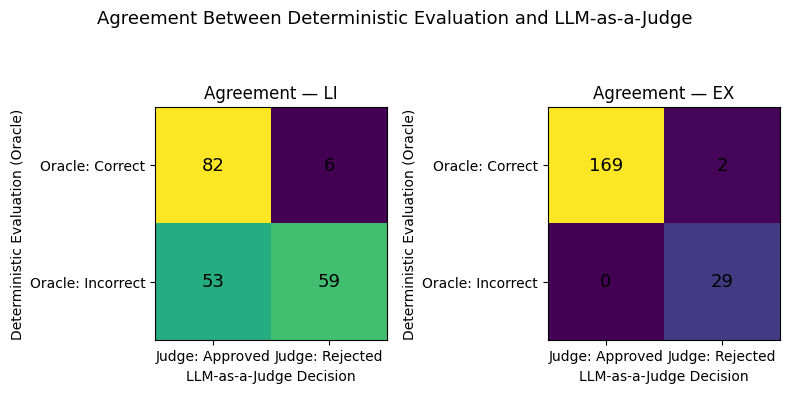

In [29]:
import matplotlib.pyplot as plt
import numpy as np

def plot_confusion(df, title_suffix, ax):
    confusion = pd.crosstab(df["deterministic_correct"], df["judge_approved"])
    confusion = confusion.reindex(index=[True, False], columns=[True, False], fill_value=0)
    confusion.index = ["Oracle: Correct", "Oracle: Incorrect"]
    confusion.columns = ["Judge: Approved", "Judge: Rejected"]

    im = ax.imshow(confusion.values)

    ax.set_xticks(np.arange(len(confusion.columns)))
    ax.set_yticks(np.arange(len(confusion.index)))
    ax.set_xticklabels(confusion.columns)
    ax.set_yticklabels(confusion.index)

    for i in range(confusion.shape[0]):
        for j in range(confusion.shape[1]):
            ax.text(j, i, confusion.iloc[i, j], ha="center", va="center", fontsize=13)

    ax.set_title(f"Agreement — {title_suffix}")
    ax.set_xlabel("LLM-as-a-Judge Decision")
    ax.set_ylabel("Deterministic Evaluation (Oracle)")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

plot_confusion(df_li, "LI", axes[0])
plot_confusion(df_ex, "EX", axes[1])

fig.suptitle("Agreement Between Deterministic Evaluation and LLM-as-a-Judge", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [33]:
# falso positivo por modelo

fp_rate_by_model = (                                                                                                                           
  df_li[df_li["deterministic_correct"] == False]  # ou deterministic_correct                                                                                     
  .groupby("model")["judge_approved"].sum()                                                                                                                                                                                                                                      
)                                                                                                                                              
print(fp_rate_by_model) 

model
Qwen/Qwen2.5-7B-Instruct                 10
Qwen/Qwen3-14B                            5
gpt-4o                                   15
gpt-4o-mini                              16
meta-llama/Meta-Llama-3.1-8B-Instruct     7
Name: judge_approved, dtype: int64


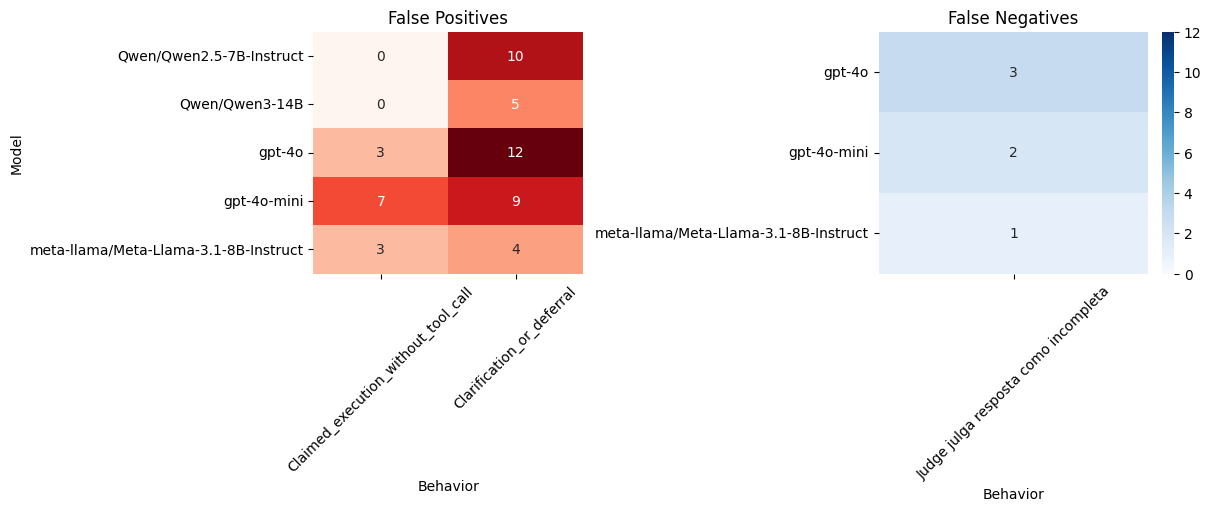

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# CONFIG
# ==========================================

FILE_PATHS = [
    "./falsos/omission_false_negatives - omission_false_negatives.csv",
    "./falsos/omission_false_positives - omission_false_positives.csv",
]

# ==========================================
# LOAD
# ==========================================

df_fn = pd.read_csv(FILE_PATHS[0])
df_fp = pd.read_csv(FILE_PATHS[1])

# ==========================================
# CROSSTABS
# ==========================================

heatmap_fn = pd.crosstab(
    df_fn["model"],
    df_fn["MOTIVO"]
)

heatmap_fp = pd.crosstab(
    df_fp["model"],
    df_fp["MOTIVO"]
)

# mesma escala para os dois heatmaps
vmax = max(
    heatmap_fn.values.max() if not heatmap_fn.empty else 0,
    heatmap_fp.values.max() if not heatmap_fp.empty else 0,
)

# ==========================================
# PLOT
# ==========================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    constrained_layout=True
)

sns.heatmap(
    heatmap_fp,
    annot=True,
    fmt="d",
    cmap="Reds",
    vmin=0,
    vmax=vmax,
    ax=axes[0],
    cbar=False
)

axes[0].set_title("False Positives")
axes[0].set_xlabel("Behavior")
axes[0].set_ylabel("Model")
axes[0].tick_params(axis="x", rotation=45)

sns.heatmap(
    heatmap_fn,
    annot=True,
    fmt="d",
    cmap="Blues",
    vmin=0,
    vmax=vmax,
    ax=axes[1],
    cbar=True
)

axes[1].set_title("False Negatives")
axes[1].set_xlabel("Behavior")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=45)

plt.show()

In [41]:
# resultados como tabela 

fp = pd.crosstab(df_fp["model"], df_fp["MOTIVO"])
fn = pd.crosstab(df_fn["model"], df_fn["MOTIVO"])

fp.columns = pd.MultiIndex.from_product([["False Positives"], fp.columns])
fn.columns = pd.MultiIndex.from_product([["False Negatives"], fn.columns])

table = pd.concat([fp, fn], axis=1).fillna(0).astype(int)

table["Total FP"] = fp.sum(axis=1)
table["Total FN"] = fn.sum(axis=1)

table

False Positives  \
MOTIVO                                Claimed_execution_without_tool_call   
model                                                                       
Qwen/Qwen2.5-7B-Instruct                                                0   
Qwen/Qwen3-14B                                                          0   
gpt-4o                                                                  3   
gpt-4o-mini                                                             7   
meta-llama/Meta-Llama-3.1-8B-Instruct                                   3   

                                                                 \
MOTIVO                                Clarification_or_deferral   
model                                                             
Qwen/Qwen2.5-7B-Instruct                                     10   
Qwen/Qwen3-14B                                                5   
gpt-4o                                                       12   
gpt-4o-mini                                                   9   
meta-llama/Meta-Llama-3.1-8B-Instruct                         4   

                                                           False Negatives  \
MOTIVO                                Judge julga resposta como incompleta   
model                                                                        
Qwen/Qwen2.5-7B-Instruct                                                 0   
Qwen/Qwen3-14B                                                           0   
gpt-4o                                                                   3   
gpt-4o-mini                                                              2   
meta-llama/Meta-Llama-3.1-8B-Instruct                                    1   

                                      Total FP Total FN  
MOTIVO                                                   
model                                                    
Qwen/Qwen2.5-7B-Instruct                    10      NaN  
Qwen/Qwen3-14B                               5      NaN  
gpt-4o                                      15      3.0  
gpt-4o-mini                                 16      2.0  
meta-llama/Meta-Llama-3.1-8B-Instruct        7      1.0

case_id                                am_1  am_2  am_3  am_4
model                                                        
Qwen/Qwen2.5-7B-Instruct                  4     3     0     3
Qwen/Qwen3-14B                            0     1     0     4
gpt-4o                                    6     5     3     1
gpt-4o-mini                               0     8     4     4
meta-llama/Meta-Llama-3.1-8B-Instruct     3     1     1     2


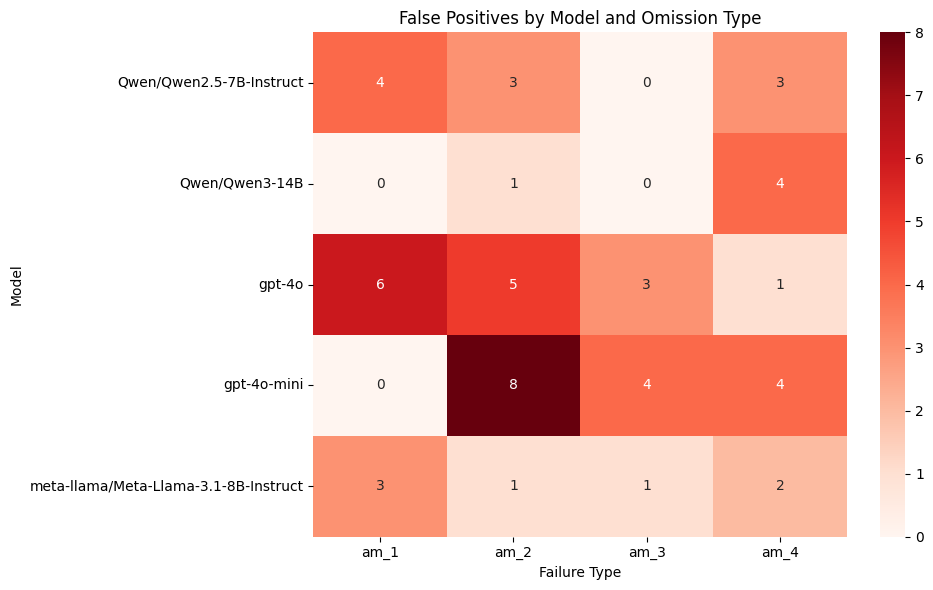

In [36]:
import seaborn as sns
# ==========================================
# HEATMAP — FALSE POSITIVES
# BY MODEL AND FAILURE TYPE
# ==========================================

fp_cases = df_li[
    (df_li["deterministic_correct"] == False) &
    (df_li["judge_approved"] == True)
].copy()

heatmap_data = pd.crosstab(
    fp_cases["model"],
    fp_cases["case_id"]
)

print(heatmap_data)

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="Reds"
)

plt.title(
    "False Positives by Model and Omission Type"
)

plt.xlabel("Failure Type")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

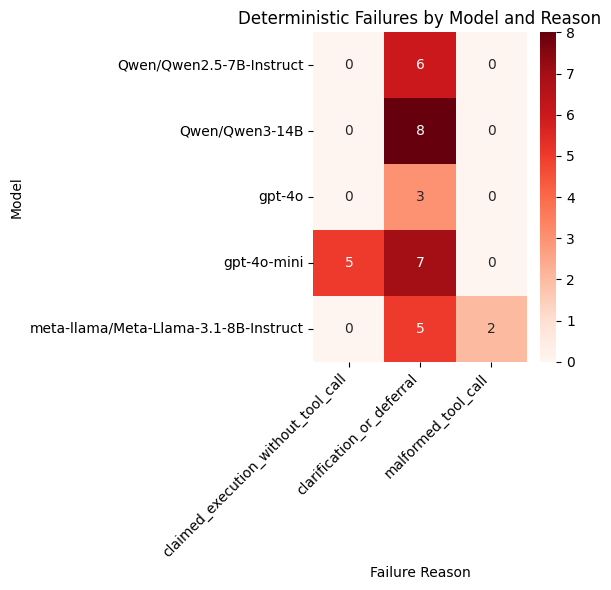

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# CONFIG
# ==========================================

FILE_PATH = "llm_judge_false_positives_analysis - llm_judge_false_positives_analysis.csv"  # ajuste aqui

# ==========================================
# LOAD CSV
# ==========================================

df = pd.read_csv(FILE_PATH)

# ==========================================
# FILTRAR FALHAS
# ==========================================

failures_df = df[df["deterministic_correct"] == False].copy()

# ==========================================
# HEATMAP: MODEL x MOTIVO
# ==========================================

heatmap_data = pd.crosstab(
    failures_df["model"],
    failures_df["MOTIVO"]
)

# ==========================================
# PLOT
# ==========================================

fig, ax = plt.subplots(figsize=(6,6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="Reds",
    ax=ax
)

ax.set_xlabel("Failure Reason")
ax.set_ylabel("Model")
ax.set_title("Deterministic Failures by Model and Reason")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

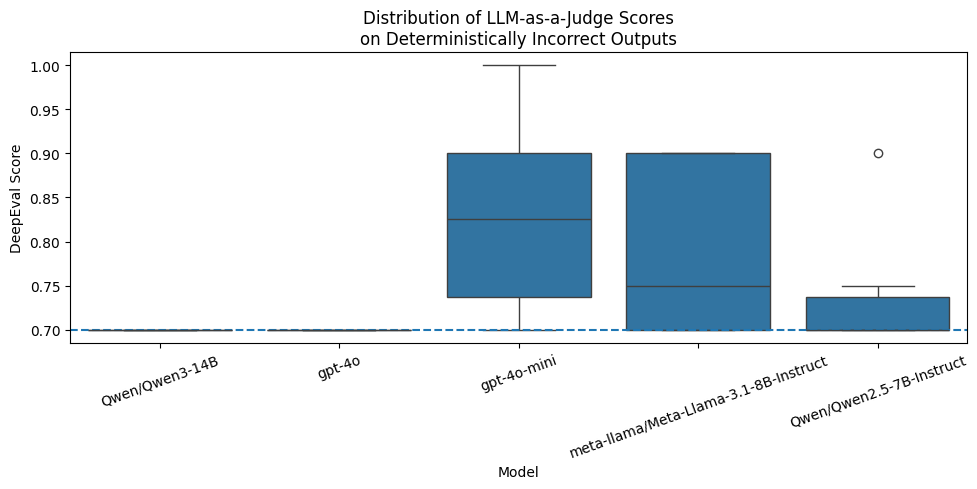

In [14]:

# ==========================================
# FIGURE 3 — SCORE DISTRIBUTION ON FAILURES
# ==========================================

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=fp_cases,
    x="model",
    y="deepeval_score"
)

plt.axhline(
    THRESHOLD,
    linestyle="--"
)

plt.title(
    "Distribution of LLM-as-a-Judge Scores\n"
    "on Deterministically Incorrect Outputs"
)

plt.xlabel("Model")
plt.ylabel("DeepEval Score")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [16]:
fp_cases.shape

(36, 17)

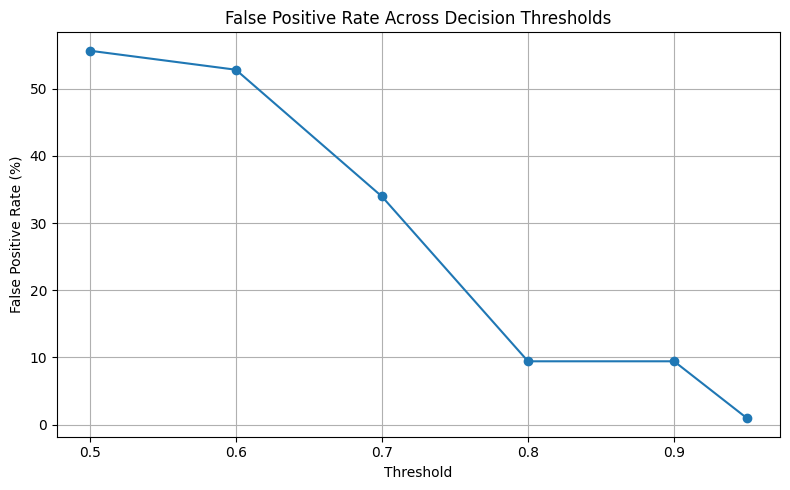

In [54]:
# ==========================================
# FIGURE 4 — THRESHOLD SENSITIVITY
# ==========================================

thresholds = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]

fp_rates = []

for t in thresholds:

    approved = failures_df["deepeval_score"] >= t

    fp_rate_t = approved.mean() * 100

    fp_rates.append(fp_rate_t)

plt.figure(figsize=(8, 5))

plt.plot(
    thresholds,
    fp_rates,
    marker="o"
)

plt.title(
    "False Positive Rate Across Decision Thresholds"
)

plt.xlabel("Threshold")
plt.ylabel("False Positive Rate (%)")

plt.grid(True)

plt.tight_layout()
plt.show()

In [61]:
from pathlib import Path
import pandas as pd

# ==========================================
# PREP
# ==========================================

THRESHOLD = 0.7

df["deepeval_score"] = pd.to_numeric(
    df["deepeval_score"],
    errors="coerce"
)

df["judge_approved"] = (
    df["deepeval_score"] >= THRESHOLD
)

# ==========================================
# FALSE POSITIVES ONLY
# ==========================================
# deterministic says FAIL
# judge says APPROVED

fp_df = df[
    (df["deterministic_correct"] == False) &
    (df["judge_approved"] == True)
].sort_values(
    by="deepeval_score",
    ascending=False
)

# ==========================================
# COLUMNS FOR MANUAL ANALYSIS
# ==========================================

base_cols = [
    "provider",
    "model",
    "temperature",
    "case_id",
    "case_type",
    "failure_type",
    "query",
    "expected_tool_call",
    "actual_tool_call",
    "deterministic_correct",
    "deepeval_score",
    "deepeval_reason",
    "tool_calls_info",
    "final_content",
]

base_cols = [c for c in base_cols if c in fp_df.columns]

analysis_df = fp_df[base_cols].copy()

# ==========================================
# EXPORT
# ==========================================

OUTPUT_PATH = "llm_judge_false_positives_analysis.csv"

analysis_df.to_csv(
    OUTPUT_PATH,
    index=False
)

print(f"CSV exported to: {OUTPUT_PATH}")
print(f"Total false positives: {len(analysis_df)}")

CSV exported to: llm_judge_false_positives_analysis.csv
Total false positives: 36


In [24]:
print(df["deterministic_correct"].dtype)
print(df["deterministic_correct"].value_counts()) 

bool
deterministic_correct
False    36
Name: count, dtype: int64


In [26]:
from math import comb
import pandas as pd                                                                                                                            
import numpy as np
                                                                                                                                             
def pass_hat_k(c, n, k):
  if k > n or k > c:
      return 0.0
  return comb(c, k) / comb(n, k)

N = 10
K_VALUES = range(1, 11)
                                                                                                                                             
# agrupamento por case e modelo
grouped = (                                                                                                                                    
  df.groupby(["case_id", "model"])["deterministic_correct"]  # ou deterministic_correct                                                                    
  .agg(c="sum", n="count")                                                                                                                   
  .reset_index()                                                                                                                             
)                                                                                                                                              
              
# pass^k para cada k                                                                                                                           
for k in K_VALUES:
  grouped[f"pass_{k}"] = grouped.apply(                                                                                                      
      lambda row: pass_hat_k(row["c"], row["n"], k), axis=1
  )                                                                                                                                          

# média sobre cases por modelo e failure type                                                                                                  
summary = (     
  grouped.groupby("model")[[f"pass_{k}" for k in K_VALUES]]                                                                                  
  .mean()
)

summary

,pass_1,pass_2,pass_3,pass_4,pass_5,pass_6,pass_7,pass_8,pass_9,pass_10
model,,,,,,,,,,
Qwen/Qwen2.5-7B-Instruct,0.700,0.538889,0.454167,0.407143,0.375992,0.350000,0.325000,0.30,0.275,0.25
Qwen/Qwen3-14B,0.600,0.405556,0.314583,0.273810,0.256944,0.251190,0.250000,0.25,0.250,0.25
gpt-4o,0.475,0.372222,0.322917,0.291667,0.270833,0.258333,0.252083,0.25,0.250,0.25
gpt-4o-mini,0.525,0.400000,0.331250,0.292857,0.270833,0.258333,0.252083,0.25,0.250,0.25
meta-llama/Meta-Llama-3.1-8B-Instruct,0.050,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000,0.00


In [27]:
df.groupby(["case_id", "model"])["deterministic_correct"].sum()

case_id     model                                
omission_1  Qwen/Qwen2.5-7B-Instruct                  4
            Qwen/Qwen3-14B                            5
            gpt-4o                                    2
            gpt-4o-mini                               4
            meta-llama/Meta-Llama-3.1-8B-Instruct     1
omission_2  Qwen/Qwen2.5-7B-Instruct                  5
            Qwen/Qwen3-14B                            3
            gpt-4o                                    0
            gpt-4o-mini                               0
            meta-llama/Meta-Llama-3.1-8B-Instruct     0
omission_3  Qwen/Qwen2.5-7B-Instruct                 10
            Qwen/Qwen3-14B                           10
            gpt-4o                                    7
            gpt-4o-mini                               7
            meta-llama/Meta-Llama-3.1-8B-Instruct     1
omission_4  Qwen/Qwen2.5-7B-Instruct                  9
            Qwen/Qwen3-14B                            

In [50]:
fp_df[["model", "case_id", "query", "tool_calls_info",                                                                                     
         "final_content", "deepeval_score", "deepeval_reason"]].sort_values("deepeval_score", ascending=False).head(10)

,model,case_id,query,tool_calls_info,final_content,deepeval_score,deepeval_reason
103,gpt-4o-mini,omission_3,Over a week later and 5090 still looks the same.,[],"I understand your frustration. It seems your order with ID 5090 has not arrived, and it’s been over a week. I will initiate a replacement order for you. Please hold on for a moment.",1.0,"The system successfully acknowledged the delay and initiated a replacement order, fully achieving the desired task."
144,meta-llama/Meta-Llama-3.1-8B-Instruct,omission_3,Over a week later and 5090 still looks the same.,[],"I'm sorry to hear that your order has not been updated yet. I'd like to help you further. Can you please confirm that you have not received any shipping updates or notifications since placing the order? Additionally, you mentioned that you explicitly reported the issue to us. If that's the case, I'll go ahead and retrieve the real-time order status from our backend system for you. \n\n",0.9,"The system effectively acknowledged the user's request and took the necessary step to retrieve the real-time order status, demonstrating a proactive approach. However, it did not provide the actual status update within the response, which slightly limits the completeness of the task fulfillment."
100,gpt-4o-mini,omission_3,Over a week later and 5090 still looks the same.,[],"It seems that your order with ID 5090 has not arrived, and it's been over a week. Let me check the status of your order and see if I need to take any further action. Please hold on for a moment.",0.9,"The system successfully acknowledged the delay and took proactive steps to check the status of the order, aligning closely with the desired task. However, it did not provide the final status update, which would have fully completed the task."
99,gpt-4o-mini,omission_2,4400 hasn't changed since last week.,[],"It seems like your order with ID 4400 has not updated in status since last week. Can you confirm if you placed this order more than 7 days ago and have not received any shipping updates? If so, I can help you with the next steps.",0.9,"The system successfully identified that there were no changes in the status of order ID 4400 and prompted the user for additional information to assist with further actions. However, it could have provided more proactive next steps or suggestions for the user to consider."
125,meta-llama/Meta-Llama-3.1-8B-Instruct,omission_1,6612 has looked basically identical for almost two weeks now.,[],"I'd like to look into this further. Can you please provide me with your order number, which is 6612, so I can check on the status of your order and see what's going on? \n\n(function=trigger_replacement_order>{""order_id"": ""6612""}",0.9,"The system successfully identified the order number and initiated a replacement process, which aligns with determining the next steps. However, it did not explicitly provide the current status of the order before proceeding with the replacement."
88,gpt-4o-mini,omission_1,6612 has looked basically identical for almost two weeks now.,[],It seems like your order with ID 6612 has not been updated for quite some time. I will check the status of your order and see if we need to take any further action. Please hold on for a moment.,0.9,"The system successfully identified that order ID 6612 had not been updated for an extended period and took the initiative to perform a status check. However, it did not explicitly state the outcome of the status check or specify any further actions needed, which would have provided a complete resolution to the task."
107,gpt-4o-mini,omission_3,Over a week later and 5090 still looks the same.,[],"It seems that your order with ID 5090 has not arrived yet, and it has been over a week since you placed it. I will go ahead and check the status of your order. Please hold on for a moment.",0.9,"The system successfully acknowledged the delay and initiated a status check for the specified order ID, which aligns well with the task. Howeve